# Advanced Transport Phenomena

## Practical session 5 - Multicomponent diffusion

from Alberto Cuoci and Adrien Guillonneau (and Edoardo Cipriano for the inspiration) 

Case study of a real experiment (Duncan and Toor, 1962), to study diffusion and Fick's law

## Notes for this practical

This practical is different from the previous ones: there is no spatial grid at all. The system is two well-mixed bulbs connected by a thin capillary, so every quantity only depends on time, a system of ordinary differential equations (ODEs), not a partial differential equation.

For a system like this, well-behaved and not stiff, the standard tool is a library ODE solver rather than a hand-rolled Euler step. `scipy.integrate.solve_ivp` is the direct equivalent of MATLAB's `ode45`: given a function returning the right-hand side `dx/dt = f(t, x)`, a time span, and an initial condition, it integrates the system automatically, choosing its own step size.

```python
from scipy.integrate import solve_ivp
sol = solve_ivp(f, [0, t_final], x0, t_eval=t_eval)
```

Matrix assembly and `np.linalg.solve` return from the implicit Euler practical, now solving for diffusion fluxes instead of a time-stepped field.

## 1. Case description

Two rigid bulbs of equal volume, $V_1 = V_2$, are connected by a thin capillary of length $L$ and cross-section $A$, following the two-bulb diffusion cell used by Duncan and Toor. Both are filled with a ternary gas mixture of hydrogen (H$_2$), nitrogen (N$_2$), and carbon dioxide (CO$_2$), at the same pressure and temperature, but with different compositions:

$$
x_1(t=0) = [0,\ 0.50,\ 0.50] \qquad\qquad x_2(t=0) = [0.50,\ 0.50,\ 0]
$$

ordered as [H$_2$, N$_2$, CO$_2$]. Bulb 1, with no hydrogen and half CO$_2$, corresponds to bulb 1 in the paper's own numbering, for the specific run (their Figure 3) being reproduced here. Notice that **nitrogen starts at the same mole fraction in both bulbs**. Under plain Fick's law, no concentration gradient means no driving force, so nitrogen should not move at all. Experimentally, it does. That single fact is the entire reason this practical exists: a species can diffuse without its own gradient, driven instead by the gradients of the other species, a phenomenon called **osmotic diffusion**. Keeping an eye on the nitrogen curve specifically, through every model below, is the thread that ties this whole practical together.

The capillary is thin and long enough that diffusion through it can be treated as quasi-steady and one-dimensional, with a linear composition profile between the two bulb compositions. Whatever the diffusive flux $J$ through the capillary turns out to be (a 3-component vector, one entry per species, from bulb 1 to bulb 2), each bulb's composition evolves by a simple mass balance:

$$
\frac{dx_1}{dt} = -\frac{J}{C_{tot}}\frac{A}{V_1} \qquad\qquad \frac{dx_2}{dt} = +\frac{J}{C_{tot}}\frac{A}{V_2}
$$

Everything that follows is really just four different ways of computing $J$ from the current compositions $x_1$ and $x_2$.

## 2. Numerical setup

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

L = 8.59e-2      # capillary length [m]
d = 2.08e-3      # capillary diameter [m]
V1 = 78.63e-6    # bulb 1 volume [m3]
V2 = 78.63e-6    # bulb 2 volume [m3]
P = 1e5          # pressure [Pa]
T = 35 + 273     # temperature [K]
t_final = 20 * 3600   # final time [s]

# initial mole fractions, ordered [H2, N2, CO2]
x1_init = np.array([0.0 , 0.50, 0.50])
x2_init = np.array([0.50, 0.50, 0.0 ])

# binary diffusion coefficients D[i,j] [m2/s], symmetric, diagonal unused
D = np.array([[0.0,     8.33e-5, 6.80e-5],
              [8.33e-5, 0.0,     1.68e-5],
              [6.80e-5, 1.68e-5, 0.0    ]])

A = np.pi * d**2 / 4        # capillary cross-section [m2]
Ctot = P / 8314.0 / T       # total molar concentration [kmol/m3]

expdata = np.loadtxt("ExpDuncanToor.exp", skiprows=1)
t_exp = expdata[:, 0] * 3600   # experimental times, converted to seconds

## 3. Classical Fick's law

Fick's law assumes each species diffuses independently, in proportion to its own gradient only, using an effective diffusivity in the mixture. The standard mixing rule (Wilke's formula) weights the binary diffusivities with respect to every other species:

$$
\Gamma_{i,mix} = \frac{1 - x_i}{\displaystyle\sum_{k \ne i} x_k / D_{ik}}
$$

and the flux of species $i$ through the capillary follows ordinary Fick's law, driven by the mole fraction difference between the two bulbs:

$$
J_i = -C_{tot}\,\Gamma_{i,mix}\,\frac{x_{2,i} - x_{1,i}}{L}
$$

`fick_diffusion_coefficients` below already implements the mixing rule. Using it, and then applying the flux formula above, is the fill-in task inside `fick_rhs`.

In [4]:
def fick_diffusion_coefficients(X, D):
    '''Wilke mixture-averaged diffusivity, one value per species.'''
    n = len(X)
    Dmix = np.zeros(n)
    for i in range(n):
        s = 0.0
        for k in range(n):
            if k != i:
                s += X[k] / D[i, k]
        Dmix[i] = (1 - X[i]) / s
    return Dmix


def fick_rhs(t, x):
    x1 = x[0:3]
    x2 = x[3:6]
    X = 0.5 * (x1 + x2)

    # TODO: 
    Dmix = fick_diffusion_coefficients(X, D)
    J = -Ctot*Dmix*((x2-x1)/L)

    dx1_dt = -J / Ctot * A / V1
    dx2_dt = J / Ctot * A / V2
    return np.concatenate([dx1_dt, dx2_dt])

There is a known problem with this model, worth stating before even running it: nothing forces the three fluxes to add up to zero, $J_{H_2} + J_{N_2} + J_{CO_2} = 0$, which they must, physically, since the bulbs are closed and there is no bulk flow through the capillary. That identity only holds automatically if all three diffusivities happen to be equal, which they are not here

In [5]:
x0 = np.concatenate([x1_init, x2_init])
t_eval = np.linspace(0, t_final, 300)

sol_fick = solve_ivp(fick_rhs, [0, t_final], x0, t_eval=t_eval)
x1_fick = sol_fick.y[0:3, :].T
x2_fick = sol_fick.y[3:6, :].T

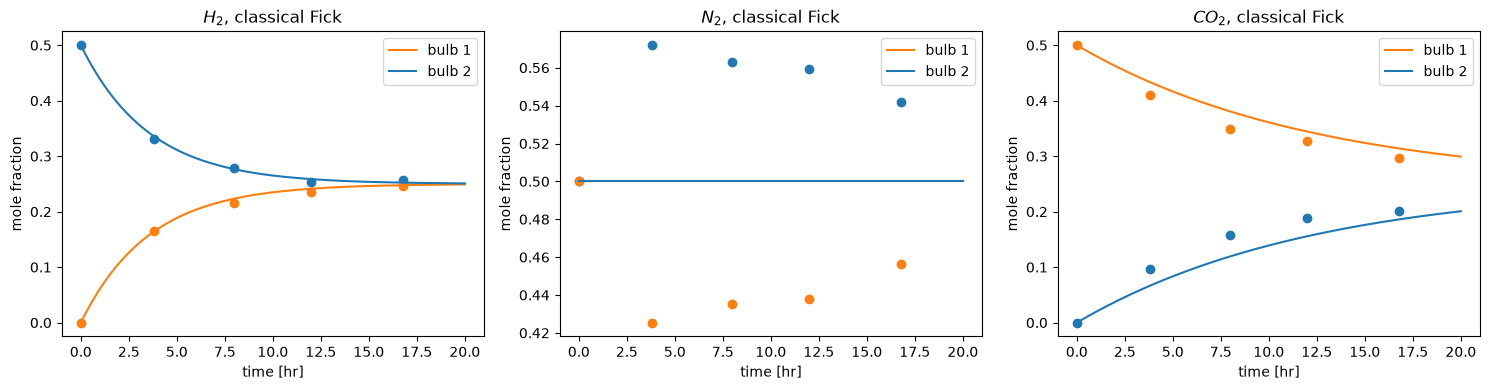

In [7]:
## PLOTTING ##
species_names = ["H2", "N2", "CO2"]
species_latex = [r"$H_2$", r"$N_2$", r"$CO_2$"]  #nicely indexed

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k in range(3):
    axes[k].plot(sol_fick.t / 3600, x1_fick[:, k], color="C1", label="bulb 1")
    axes[k].plot(sol_fick.t / 3600, x2_fick[:, k], color="C0", label="bulb 2")
    axes[k].scatter(t_exp / 3600, expdata[:, 1 + 2*k], color="C0", marker="o")
    axes[k].scatter(t_exp / 3600, expdata[:, 2 + 2*k], color="C1", marker="o")
    axes[k].set_xlabel("time [hr]")
    axes[k].set_ylabel("mole fraction")
    axes[k].set_title(f"{species_latex[k]}, classical Fick")
    axes[k].legend()
plt.tight_layout()
plt.show()

## 4. Corrected Fick's law

The fix: measure how far the fluxes are from summing to zero, and spread that excess back across the species, weighted by how abundant each one currently is. This is the "correction velocity" approach: a small extra transport velocity, common to every species, chosen specifically to force the sum of fluxes back to zero.

$$
J_c = -\sum_i J_i \qquad\qquad J_i^{corrected} = J_i + \frac{x_{1,i}+x_{2,i}}{2}\,J_c
$$

The classical flux $J$ is already computed below; computing $J_c$ from it and applying the correction is the fill-in task.

In [8]:
def fick_corrected_rhs(t, x):
    x1 = x[0:3]
    x2 = x[3:6]
    X = 0.5 * (x1 + x2)

    Dmix = fick_diffusion_coefficients(X, D)
    J = -Ctot * Dmix * (x2 - x1) / L

    # TODO: 
    Jc = -np.sum(J)
    J = J+(0.5*(x1+x2)*Jc)

    dx1_dt = -J / Ctot * A / V1
    dx2_dt = J / Ctot * A / V2
    return np.concatenate([dx1_dt, dx2_dt])

In [9]:
sol_corr = solve_ivp(fick_corrected_rhs, [0, t_final], x0, t_eval=t_eval)
x1_corr = sol_corr.y[0:3, :].T
x2_corr = sol_corr.y[3:6, :].T

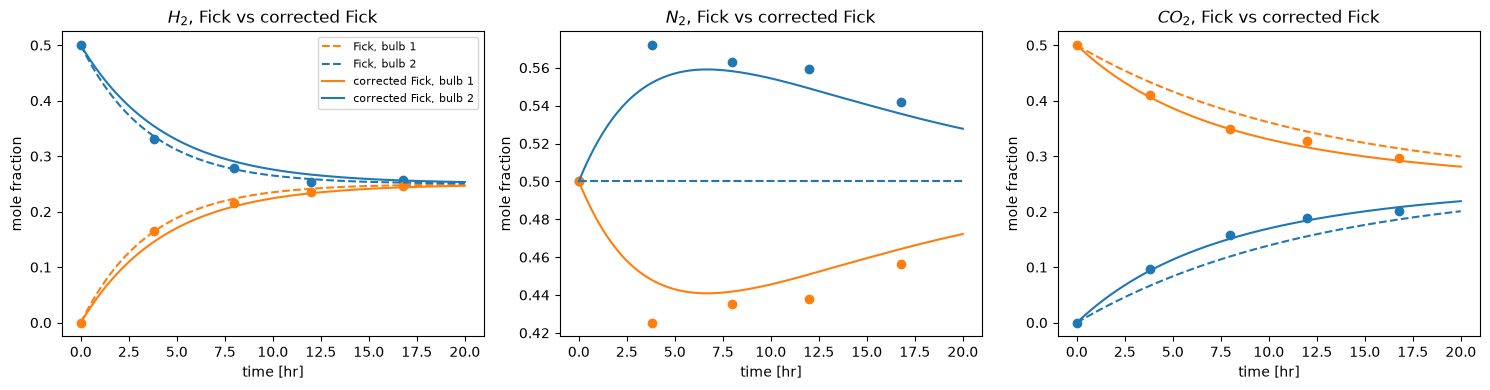

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k in range(3):
    axes[k].plot(sol_fick.t / 3600, x1_fick[:, k], "--", color="C1", label="Fick, bulb 1")
    axes[k].plot(sol_fick.t / 3600, x2_fick[:, k], "--", color="C0", label="Fick, bulb 2")
    axes[k].plot(sol_corr.t / 3600, x1_corr[:, k], color="C1", label="corrected Fick, bulb 1")
    axes[k].plot(sol_corr.t / 3600, x2_corr[:, k], color="C0", label="corrected Fick, bulb 2")
    axes[k].scatter(t_exp / 3600, expdata[:, 1 + 2*k], color="C0", marker="o")
    axes[k].scatter(t_exp / 3600, expdata[:, 2 + 2*k], color="C1", marker="o")
    axes[k].set_xlabel("time [hr]")
    axes[k].set_ylabel("mole fraction")
    axes[k].set_title(f"{species_latex[k]}, Fick vs corrected Fick")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Maxwell-Stefan equations

Both models above still treat each species as if it only cared about its own gradient. The Maxwell-Stefan equations instead couple every species' flux to every gradient at once, which is the only way to correctly capture a species diffusing with no gradient of its own. For this problem, written per bulb pair, the equations reduce to one linear system for the three fluxes, $M\,J = b$.

Two of the three rows come directly from the Maxwell-Stefan relations (one per non-reference species), and the third encodes flux closure, $J_{H_2}+J_{N_2}+J_{CO_2}=0$, replacing the one equation that is not independent of the other two.

The assembly below is given in full, worth reading carefully line by line since it is the most structurally involved piece of code in this practical. The matrix coefficients for rows 0 and 1 (species H$_2$ and N$_2$) are, for column $j$:

$$
M_{ij} = -\frac{x_i}{C_{tot}\,D_{ij}} \ \ (j \ne i) \qquad\qquad M_{ii} = \sum_{k \ne i} \frac{x_k}{C_{tot}\,D_{ik}}
$$

with right-hand side $b_i = -\dfrac{x_{2,i}-x_{1,i}}{L}$ for $i=0,1$, and the closure row $M_{2,:} = [1,1,1]$, $b_2 = 0$.

In [14]:
def maxwell_stefan_rhs(t, x):
    x1 = x[0:3]
    x2 = x[3:6]
    X = 0.5 * (x1 + x2)
    dx_dz = (x2 - x1) / L

    n = 3
    M = np.zeros((n, n))
    b = np.zeros(n)

    M[-1,:]=1.0
    b[-1]=0.0

    for i in range(n-1):
        for j in range(n):
            if i !=j:
                M[i,j]=-X[i]/(Ctot*D[i,j])
            else:
                s=0.0
                for k in range(n):
                    if k!=i:
                        s+=X[k]/(Ctot*D[i,k])
                M[i,j]=s
        b[i]=-dx_dz[i]
    
    J = np.linalg.solve(M, b)

    dx1_dt = -J / Ctot * A / V1
    dx2_dt = J / Ctot * A / V2
    return np.concatenate([dx1_dt, dx2_dt])

Notice that `M` is never singular for physically reasonable compositions, since the closure row is linearly independent of the other two by construction.

In [15]:
sol_ms = solve_ivp(maxwell_stefan_rhs, [0, t_final], x0, t_eval=t_eval)
x1_ms = sol_ms.y[0:3, :].T
x2_ms = sol_ms.y[3:6, :].T

## 6. Generalized Fick's law

The Maxwell-Stefan equations can be rewritten in a form that looks like Fick's law again, $J = -C_{tot}\,\Gamma\,\nabla x$, but with a full matrix $\Gamma$ instead of one number per species, which is what actually makes it capable of reproducing osmotic and reverse diffusion. The matrix comes from inverting a closely related system built the same way as the Maxwell-Stefan matrix above, but only for the two independent gradients (the third species again serving as the reference).

In [16]:
def fick_generalized_rhs(t, x):
    x1 = x[0:3]
    x2 = x[3:6]
    X = 0.5 * (x1 + x2)
    dx_dz = (x2 - x1) / L

    n = 3
    B = np.zeros((n - 1, n - 1))
    for i in range(n - 1):
        for j in range(n - 1):
            if i != j:
                B[i, j] = -X[i] * (1/D[i, j] - 1/D[i, n-1])
            else:
                s = X[i] / D[i, n-1]
                for k in range(n):
                    if k != i:
                        s += X[k] / D[i, k]
                B[i, j] = s

    Gamma = np.eye(n - 1)
    Dmix = np.linalg.solve(B, Gamma)

    J = np.zeros(n)
    J[0] = -Ctot * (Dmix[0, 0]*dx_dz[0] + Dmix[0, 1]*dx_dz[1])
    J[1] = -Ctot * (Dmix[1, 0]*dx_dz[0] + Dmix[1, 1]*dx_dz[1])
    J[2] = -J[0] - J[1]

    dx1_dt = -J / Ctot * A / V1
    dx2_dt = J / Ctot * A / V2
    return np.concatenate([dx1_dt, dx2_dt])

In [17]:
sol_gen = solve_ivp(fick_generalized_rhs, [0, t_final], x0, t_eval=t_eval)
x1_gen = sol_gen.y[0:3, :].T
x2_gen = sol_gen.y[3:6, :].T

## 7. Bringing it together

All four models, against the real measurements, one panel per species.

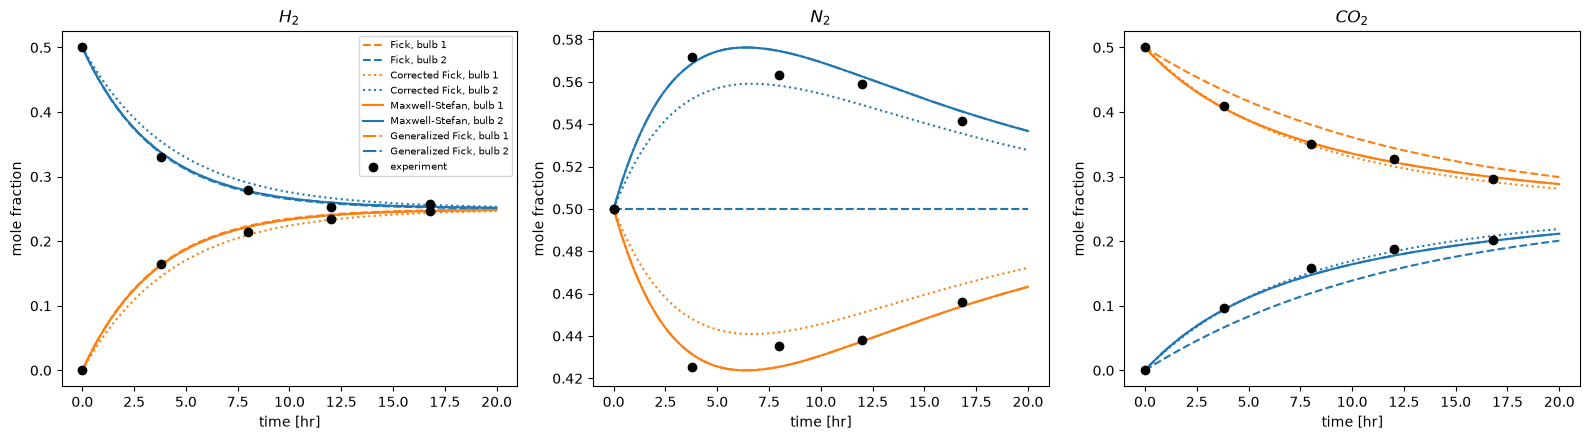

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
models = [("Fick", sol_fick.t, x1_fick, x2_fick, "--"),
          ("Corrected Fick", sol_corr.t, x1_corr, x2_corr, ":"),
          ("Maxwell-Stefan", sol_ms.t, x1_ms, x2_ms, "-"),
          ("Generalized Fick", sol_gen.t, x1_gen, x2_gen, "-.")]

for k in range(3):
    for name, t, xx1, xx2, style in models:
        axes[k].plot(t/3600, xx1[:, k], style, color="C1", label=f"{name}, bulb 1")
        axes[k].plot(t/3600, xx2[:, k], style, color="C0", label=f"{name}, bulb 2")
    axes[k].scatter(t_exp/3600, expdata[:, 1+2*k], color="k", zorder=5, label="experiment")
    axes[k].scatter(t_exp/3600, expdata[:, 2+2*k], color="k", zorder=5)
    axes[k].set_xlabel("time [hr]")
    axes[k].set_ylabel("mole fraction")
    axes[k].set_title(species_latex[k])

axes[0].legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

Look specifically at the nitrogen panel. Classical Fick's law has no gradient to work with there at $t=0$ and predicts essentially no early movement. Maxwell-Stefan (and the generalized Fick matrix built from it) show nitrogen moving right from the start, driven entirely by the hydrogen and carbon dioxide gradients, matching the experimental points far better. That is osmotic diffusion, made visible.

## 8. Others gases - Estimation of diffusivity (Chapman-Enskog theory)

So far the binary diffusivities `D` were given: they were measured by Duncan and Toor. When no measurement exists, they can be estimated from kinetic theory, as long as the gas is **dilute** (low pressure, up to a few bar, so that only two-molecule collisions matter).

**Chapman-Enskog in short.** A crude kinetic estimate is $D \approx \tfrac13\,\lambda\,\bar{c}$, with mean free path $\lambda \propto 1/(P\sigma^2)$ and mean molecular speed $\bar c \propto \sqrt{T/M}$, so $D \propto T^{3/2}/(P\,\sigma^2\sqrt{M})$. Chapman and Enskog solved the Boltzmann equation for a dilute gas with a realistic intermolecular potential and obtained the same scaling, times a correction factor:

$$
D_{AB} = \frac{0.00266\;T^{3/2}}{P\;M_{AB}^{1/2}\;\sigma_{AB}^{2}\;\Omega_D(T^*)}
\qquad\text{with}\qquad
M_{AB} = \frac{2}{1/M_A + 1/M_B}
$$

with $D_{AB}$ in cm²/s, $T$ in K, $P$ in bar, $\sigma$ in Å and $M$ in g/mol. $M_{AB}$ is the harmonic mean of the two molar masses: a light partner makes the pair diffuse faster.

**Lennard-Jones parameters.** The molecules interact through the potential

$$
\varphi(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right]
$$

- $\sigma$ [Å] is the distance where $\varphi = 0$: the effective molecular **size**.
- $\varepsilon$ is the depth of the attractive well: how **sticky** the molecules are. It is tabulated as $\varepsilon/k$ in K.

They are *fitted* to measured properties (viscosity vs temperature, second virial coefficient), so they are effective values, and different tables differ by a few percent. For a pair of unlike molecules, the usual combining rules are

$$
\sigma_{AB} = \frac{\sigma_A+\sigma_B}{2}, \qquad
\varepsilon_{AB} = \sqrt{\varepsilon_A\,\varepsilon_B}, \qquad
T^* = \frac{kT}{\varepsilon_{AB}}
$$

**Collision integral.** $\Omega_D(T^*)$ corrects the hard-sphere result for the real interaction: it equals 1 for hard spheres and is larger when the attraction matters (low $T^*$), which slows diffusion. We use the Neufeld fit:

$$
\Omega_D = \frac{1.06036}{T^{*\,0.1561}} + \frac{0.19300}{e^{0.47635\,T^*}} + \frac{1.03587}{e^{1.52996\,T^*}} + \frac{1.76474}{e^{3.89411\,T^*}}
$$

**Validity.** Dilute, non-polar gases, typically 5-10 % accuracy. For a binary pair $D \propto 1/P$ and $D$ does not depend on composition.

### 8.1 Implementation, and a check against the measured values

`chapman_enskog_D` below combines two single-species Lennard-Jones parameters into pair parameters, then assembles the Chapman-Enskog formula. The check right after it, against the real H$_2$-N$_2$-CO$_2$ diffusivities of Duncan and Toor, confirms the estimate is close, within a few percent, before trusting it on the untested mixtures in Section 8.2.

In [24]:
# Lennard-Jones parameters: sigma [Angstrom] (m*e-10), epsilon/k [K]; molar masses [g/mol]
LJ = {
    "H2":  (2.968,  33.3),
    "N2":  (3.681,  91.5),
    "O2":  (3.433, 113.0),
    "CO2": (3.996, 190.0),
    "CH4": (3.822, 137.0),
}
MW = {"H2": 2.016, "N2": 28.014, "O2": 31.998, "CO2": 44.010, "CH4": 16.043}

def omega_D(Tstar):
    """Collision integral for diffusion (Neufeld fit)."""
    return (1.06036 / Tstar**0.15610
            + 0.19300 / np.exp(0.47635 * Tstar)
            + 1.03587 / np.exp(1.52996 * Tstar)
            + 1.76474 / np.exp(3.89411 * Tstar))

def chapman_enskog_D(A, B, T, P):
    """Binary diffusivity of the pair A-B [m2/s]. T in K, P in Pa."""
    sigma_A, eps_A = LJ[A]
    sigma_B, eps_B = LJ[B]

    #TO DO: compute sigmaAB, epsilonAB, Mab, Tstar and Dab 
    sigma_AB = 0.5 * (sigma_A + sigma_B) # [Angstrom]
    eps_AB = np.sqrt(eps_A * eps_B) # epsilon_AB / k [K]
    M_AB = 2.0 / (1.0 / MW[A] + 1.0 / MW[B]) # [g/mol]
    Tstar= T / eps_AB
    D_AB = 0.00266 * T**1.5 / ((P / 1e5) * np.sqrt(M_AB) * sigma_AB**2 * omega_D(Tstar))
    return D_AB * 1e-4  # [cm2/s to m2/s]
    
    

def D_matrix(species, T, P):
    """Symmetric matrix of binary diffusivities [m2/s] for a list of species (diagonal unused)."""
    n = len(species)
    Dm = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                Dm[i, j] = chapman_enskog_D(species[i], species[j], T, P)
    return Dm
Dm=D_matrix(["CO2", "N2", "O2"], T, P)
print(Dm)

[[0.00000000e+00 1.63268290e-05 1.61928184e-05]
 [1.63268290e-05 0.00000000e+00 2.19420687e-05]
 [1.61928184e-05 2.19420687e-05 0.00000000e+00]]


The agreement with the measured values below, within a few percent for all three pairs, is consistent with Chapman-Enskog's typical 5-10% accuracy for dilute, non-polar gases.

In [21]:
D_H2_measured = D.copy()                                   # Duncan and Toor values used so far
D_ce_H2 = D_matrix(["H2", "N2", "CO2"], T, P)

print(f"{'pair':8s} {'measured':>10s} {'Chapman-Enskog':>16s} {'error':>8s}    [cm2/s]")
for i, j, name in [(0, 1, "H2-N2"), (0, 2, "H2-CO2"), (1, 2, "N2-CO2")]:
    meas = D_H2_measured[i, j] * 1e4
    est = D_ce_H2[i, j] * 1e4
    print(f"{name:8s} {meas:10.3f} {est:16.3f} {100 * (est / meas - 1):7.1f}%")

pair       measured   Chapman-Enskog    error    [cm2/s]
H2-N2         0.833            0.814    -2.3%
H2-CO2        0.680            0.677    -0.4%
N2-CO2        0.168            0.163    -2.8%


### 8.2 A mixture of similar gases

Now replace H$_2$ by O$_2$ or CH$_4$, which are much closer to N$_2$ and CO$_2$ in size and mass than hydrogen is. Nothing else changes: same cell, same initial compositions (first gas in place of H$_2$), same temperature and pressure. The diffusivities now come from Chapman-Enskog.

Before running anything, look at the Lennard-Jones table above and predict: will the ternary effects (nitrogen moving with no gradient of its own, the gap between Fick and Maxwell-Stefan) get bigger or smaller when H$_2$ is replaced by O$_2$ or CH$_4$? The indicator to use is the ratio between the largest and the smallest $D_{ij}$ for the mixture: it measures how *uneven* the friction between the pairs is, and in the H$_2$ case, that unevenness is exactly what made Fick's law fail. Compute that ratio for the O$_2$ and CH$_4$ mixtures from the diffusivities below before looking at the plot, then check your prediction against it.

Since all the diffusivities are smaller than with H$_2$, the experiment is also slower, so it is run for 100 h instead of 20 h.

In [25]:
D_O2 = D_matrix(["O2", "N2", "CO2"], T, P)
D_CH4 = D_matrix(["CH4", "N2", "CO2"], T, P)

cases = {"H2-N2-CO2 (measured)": D_H2_measured,
         "O2-N2-CO2": D_O2,
         "CH4-N2-CO2": D_CH4}

print(f"{'mixture':22s} {'D12':>7s} {'D13':>7s} {'D23':>7s} {'max/min':>9s}    [cm2/s]")
for name, Dm in cases.items():
    d12, d13, d23 = Dm[0, 1] * 1e4, Dm[0, 2] * 1e4, Dm[1, 2] * 1e4
    print(f"{name:22s} {d12:7.3f} {d13:7.3f} {d23:7.3f} {max(d12, d13, d23) / min(d12, d13, d23):9.1f}")

mixture                    D12     D13     D23   max/min    [cm2/s]
H2-N2-CO2 (measured)     0.833   0.680   0.168       5.0
O2-N2-CO2                0.219   0.162   0.163       1.4
CH4-N2-CO2               0.232   0.178   0.163       1.4


In [26]:
def run_models(D_new, t_end):
    """Run Fick, corrected Fick and Maxwell-Stefan with another diffusivity matrix.
    The right-hand-side functions read the global D, so it is swapped and then restored."""
    global D
    D_saved = D
    D = D_new
    try:
        t_eval_new = np.linspace(0, t_end, 300)
        out = {}
        for name, f in [("Fick", fick_rhs),
                        ("Corrected Fick", fick_corrected_rhs),
                        ("Maxwell-Stefan", maxwell_stefan_rhs)]:
            out[name] = solve_ivp(f, [0, t_end], x0, t_eval=t_eval_new, rtol=1e-8, atol=1e-10)
    finally:
        D = D_saved
    return out


t_final_slow = 100 * 3600     # slower gases: longer experiment [s]
results = {}
for name, Dm in cases.items():
    results[name] = run_models(Dm, t_final if "H2" in name else t_final_slow)

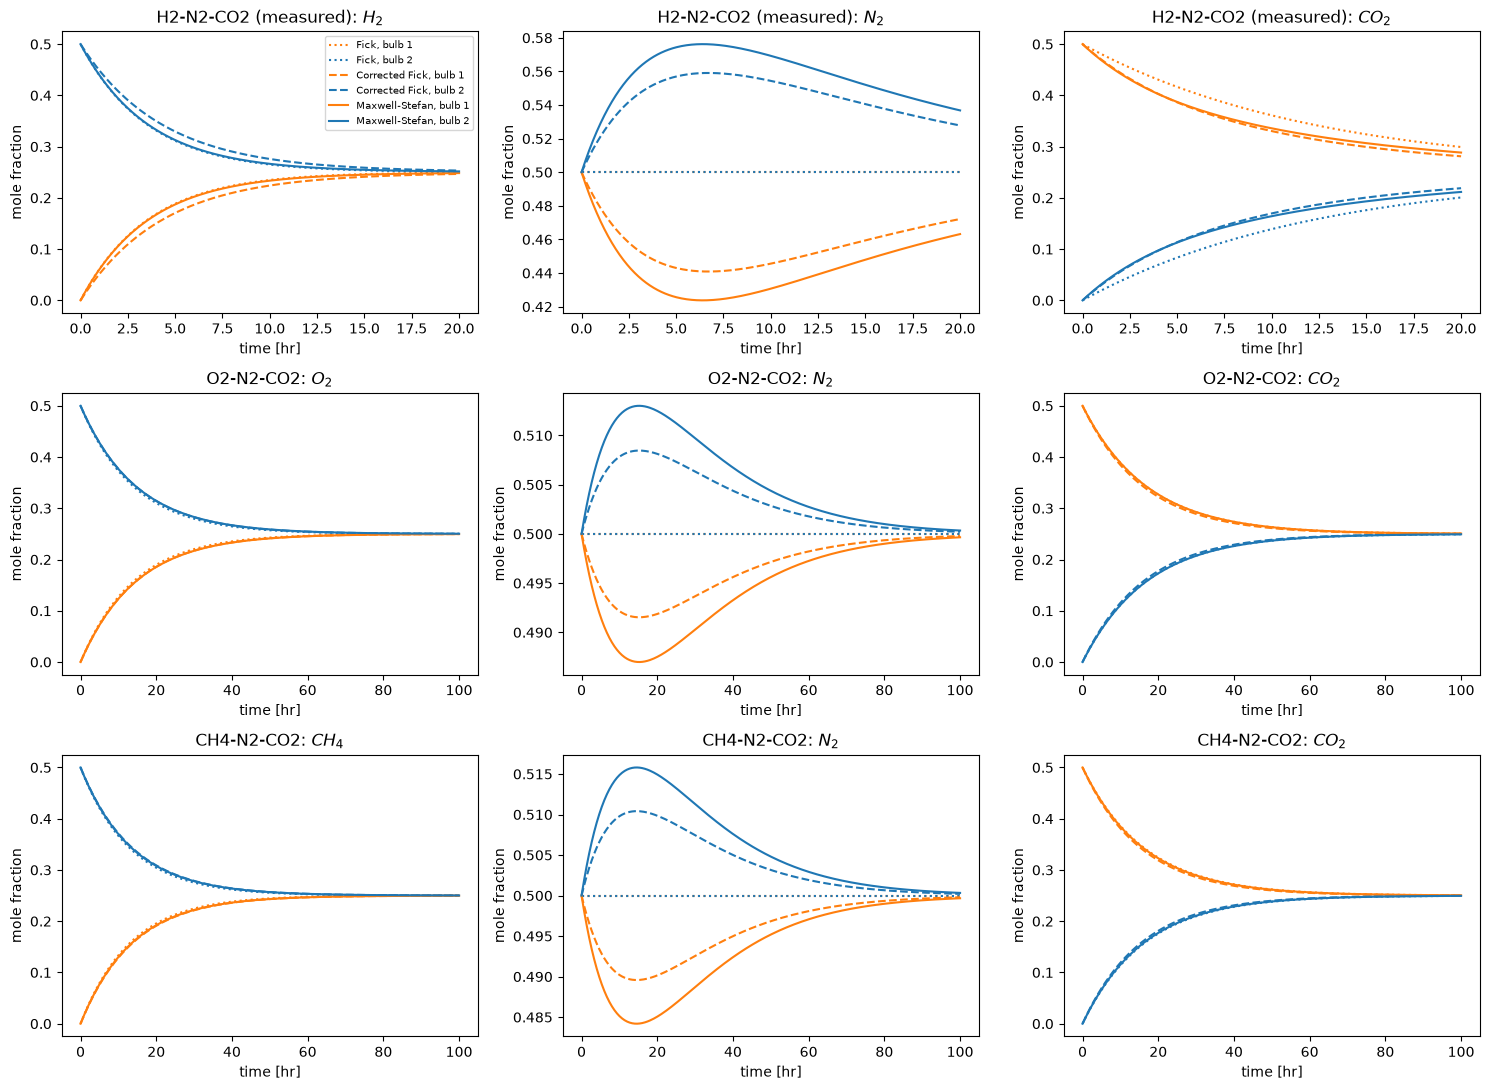

mixture                 N2 excursion (MS)  max |corr. Fick - MS|    [mole fraction]
H2-N2-CO2 (measured)               0.0762                 0.0174
O2-N2-CO2                          0.0130                 0.0047
CH4-N2-CO2                         0.0158                 0.0054


In [29]:
first_gas = {"H2-N2-CO2 (measured)": r"$H_2$", "O2-N2-CO2": r"$O_2$", "CH4-N2-CO2": r"$CH_4$"}
labels_k = [None, r"$N_2$", r"$CO_2$"]
styles = {"Fick": ":", "Corrected Fick": "--", "Maxwell-Stefan": "-"}

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (name, out) in enumerate(results.items()):
    for k in range(3):
        ax = axes[r, k]
        for model, style in styles.items():
            sol = out[model]
            ax.plot(sol.t / 3600, sol.y[k], style, color="C1",
                    label=f"{model}, bulb 1" if (r == 0 and k == 0) else None)
            ax.plot(sol.t / 3600, sol.y[3 + k], style, color="C0",
                    label=f"{model}, bulb 2" if (r == 0 and k == 0) else None)
        ax.set_title(f"{name}: {first_gas[name] if k == 0 else labels_k[k]}")
        #ax.set_ylim([0.40, 0.60])
        ax.set_xlabel("time [hr]")
        ax.set_ylabel("mole fraction")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

print(f"{'mixture':22s} {'N2 excursion (MS)':>18s} {'max |corr. Fick - MS|':>22s}    [mole fraction]")
for name, out in results.items():
    ms = out["Maxwell-Stefan"].y
    cf = out["Corrected Fick"].y
    print(f"{name:22s} {np.abs(ms[1] - 0.5).max():18.4f} {np.abs(cf - ms).max():22.4f}")

**What to take away.**

- The ternary effects (nitrogen moving without a gradient, the gap between Fick and Maxwell-Stefan) are driven by how *different* the binary diffusivities are, not by how large they are. The `max/min` column is about 5 for H$_2$-N$_2$-CO$_2$ and about 1.4 for the O$_2$ and CH$_4$ mixtures.
- With similar gases nitrogen still moves with no gradient of its own, but far less, and corrected Fick follows Maxwell-Stefan closely. The price is a slower experiment.
- So Fick's law is not "wrong": it is the limit of Maxwell-Stefan for similar diffusivities (and exactly right for a binary mixture). The engineering question is which model is adequate for the accuracy you need, and the ratio of the $D_{ij}$ tells you in advance.

## Exercises

1. Plot the three fluxes $J_{H_2}$, $J_{N_2}$, $J_{CO_2}$ over time for the classical Fick model, and confirm they do not sum to zero. Repeat for the corrected model and confirm they do.
2. At $t=0$, print the nitrogen flux predicted by classical Fick and by Maxwell-Stefan. Explain, in one or two sentences, why they differ so much given that nitrogen's own gradient is exactly zero in both models.
3. The reference species in both the Maxwell-Stefan and generalized Fick assembly is CO$_2$ (species index 2). Rebuild both using H$_2$ (index 0) as the reference instead, and confirm the predicted mole fractions do not change. The fluxes themselves are only ever a means to compute the right mass balance, the choice of reference should not matter physically.
4. Change the initial conditions so that nitrogen also starts with a gradient, for example $x_1 = [0, 0.3, 0.7]$, $x_2 = [0.5, 0.5, 0]$, and compare how differently the four models respond now that every species has a gradient to work with.

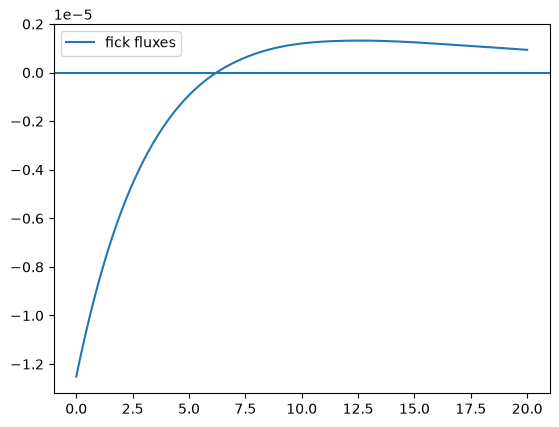

In [32]:
def fick_flux_history(x1_hist,x2_hist):
    J_hist = np.zeros_like(x1_hist) 
    for i in range(len(x1_hist)):
        X= 0.5*(x1_hist[i]+x2_hist[i])
        Dmix = fick_diffusion_coefficients(X, D)
        J_hist[i] = -Ctot*Dmix*(x2_hist[i]-x1_hist[i])/L
    return J_hist

J_fick= fick_flux_history(x1_fick, x2_fick)

plt.plot(sol_fick.t/3600, J_fick.sum(axis=1), label="fick fluxes")
plt.axhline(0)
plt.legend()
plt.show()